# Do ensembles of trees get worse when we add more trees, in regression

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

We train a random forest, an AdaBoost and a gradient boosting machine, and we follow the error in the test set after every tree that we add.

We do this first with artificial targets that we shape ourselves, then with five real datasets, then with the same five datasets after we take the logarithm of the target, and at the end we look at what the learning rate does to the two boosting models.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import (
    fetch_california_housing,
    fetch_openml,
    make_regression,
)
from sklearn.ensemble import (
    AdaBoostRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

N_ESTIMATORS = 1000
MODELS = ["random forest", "adaboost", "gradient boosting"]

### The experiment

The two boosting models give us the error after each tree with `staged_predict`.

The random forest does not, because its trees are independent and the order in which we add them is arbitrary, so we ask every tree for its prediction and we average the first tree, then the first two, then the first three, and so on, which is the forest that we would have obtained with that many trees.

In [2]:
def prepare(X, y):
    X = pd.DataFrame(X).copy()
    for var in X.columns:
        if str(X[var].dtype) in ("object", "category", "str"):
            X[var] = X[var].astype("category").cat.codes
    X = X.astype(float).fillna(-1)
    return X, pd.Series(np.asarray(y, dtype=float))


def make_model(name, n_estimators, learning_rate=1.0):
    if name == "random forest":
        return RandomForestRegressor(n_estimators=n_estimators, random_state=0, n_jobs=-1)
    if name == "adaboost":
        return AdaBoostRegressor(
            n_estimators=n_estimators, learning_rate=learning_rate, random_state=0
        )
    return GradientBoostingRegressor(
        n_estimators=n_estimators, learning_rate=learning_rate, random_state=0
    )

In [3]:
def rmse_curve(name, X, y, n_estimators=N_ESTIMATORS, learning_rate=0.1):
    X, y = prepare(X, y)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
    model = make_model(name, n_estimators, learning_rate)
    model.fit(X_train, y_train)

    if name == "random forest":
        trees = np.array([tree.predict(X_test.to_numpy()) for tree in model.estimators_])
        predictions = np.cumsum(trees, axis=0) / np.arange(1, len(trees) + 1)[:, None]
    else:
        predictions = model.staged_predict(X_test)

    errors = [root_mean_squared_error(y_test, p) for p in predictions]
    return pd.Series(errors, index=range(1, len(errors) + 1))


def lost_from_best(curve):
    return 100 * (curve.iloc[-1] - curve.min()) / curve.min()

### Artificial data

We make one set of features and we use it with three targets, one that follows a normal distribution, one that is log normal, and one that is normal except for one percent of the observations that we move far away from the rest.

In [4]:
X, y = make_regression(n_samples=6000, n_features=20, n_informative=6, noise=10.0, random_state=0)
z = (y - y.mean()) / y.std()

with_outliers = y.copy()
extreme = np.random.default_rng(0).choice(len(y), 60, replace=False)
with_outliers[extreme] = with_outliers[extreme] + 20 * y.std()

targets = {"normal": y, "log normal": np.exp(z), "normal with 1% extreme values": with_outliers}

artificial = {
    (name, shape): rmse_curve(name, X, target)
    for name in MODELS
    for shape, target in targets.items()
}

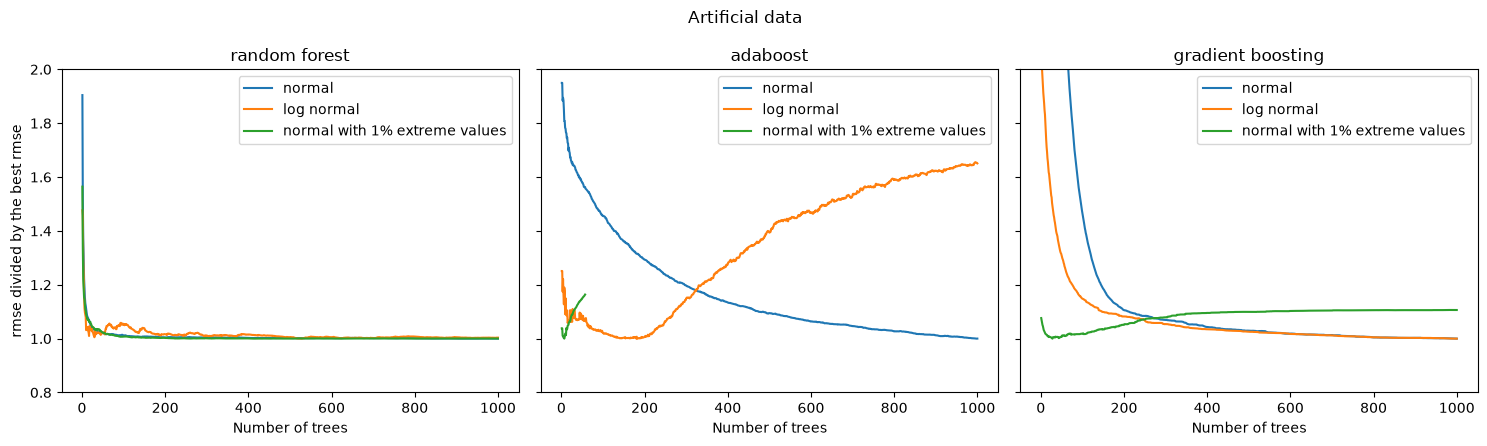

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, MODELS):
    for shape in targets:
        curve = artificial[(name, shape)]
        ax.plot(curve.index, curve / curve.min(), label=shape)
    ax.set_xlabel("Number of trees")
    ax.set_title(name)
    ax.legend()
axes[0].set_ylabel("rmse divided by the best rmse")
axes[0].set_ylim(0.8, 2)
fig.suptitle("Artificial data")
fig.tight_layout()
plt.show()

### Real datasets

We use five datasets.

In [6]:
rent = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")
house_sales = fetch_openml(data_id=42731, as_frame=True)
california = fetch_california_housing(as_frame=True)
ames = fetch_openml(data_id=42165, as_frame=True)
abalone = fetch_openml(data_id=44956, as_frame=True)

datasets = {
    "apartment rent": (rent.drop(columns="price"), rent["price"]),
    "house sales": (house_sales.data, house_sales.target),
    "california housing": (california.data, california.target),
    "ames housing": (ames.data, ames.target),
    "abalone": (abalone.data, abalone.target),
}

The targets are prices and counts, so they are positive and they have a long right tail. We look at them before and after we take the logarithm.

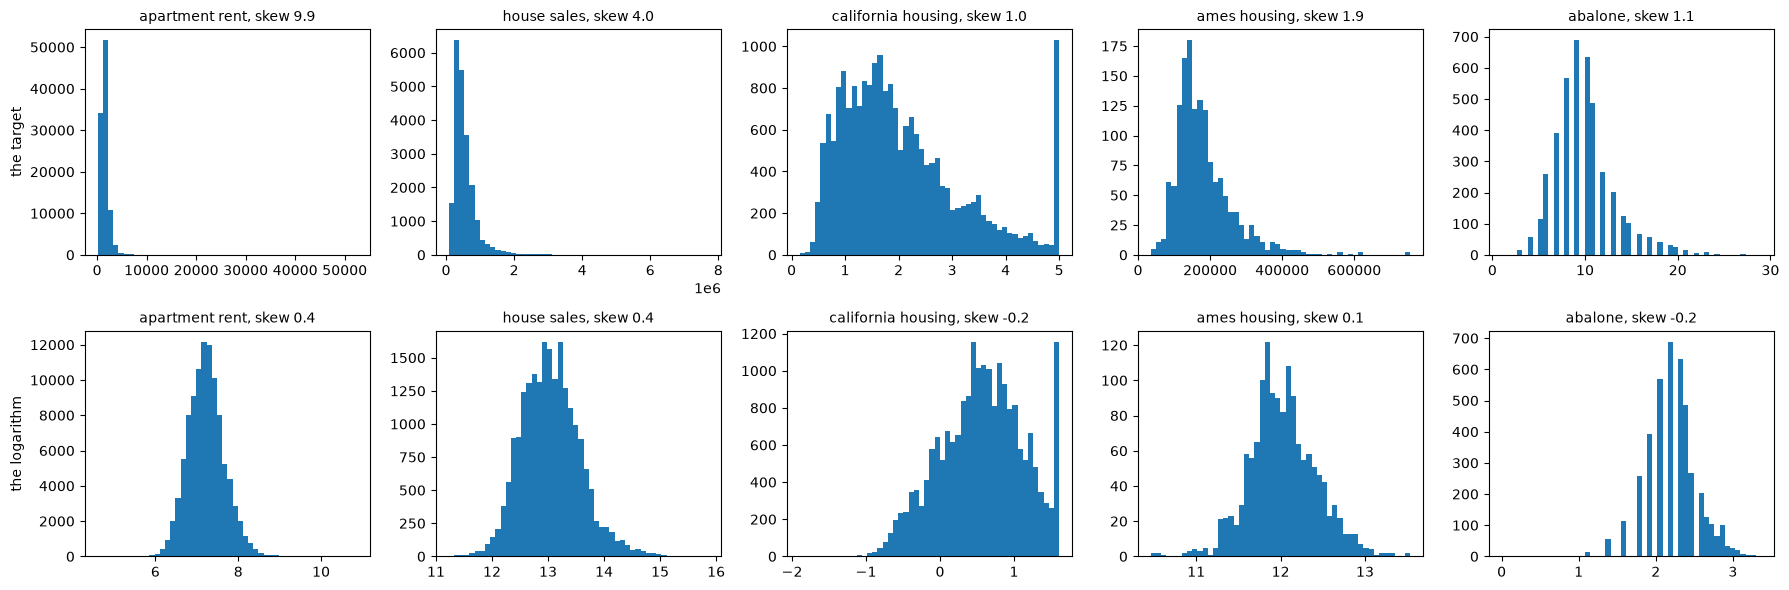

In [7]:
logged = {name: (X, np.log(pd.Series(np.asarray(y, dtype=float)))) for name, (X, y) in datasets.items()}

fig, axes = plt.subplots(2, len(datasets), figsize=(18, 6))
for column, name in enumerate(datasets):
    for row, source in enumerate([datasets, logged]):
        target = pd.Series(np.asarray(source[name][1], dtype=float))
        axes[row][column].hist(target, bins=50)
        axes[row][column].set_title(f"{name}, skew {target.skew():.1f}", fontsize=10)
axes[0][0].set_ylabel("the target")
axes[1][0].set_ylabel("the logarithm")
fig.tight_layout()
plt.show()

In [8]:
real = {
    (name, dataset): rmse_curve(name, X, y)
    for name in MODELS
    for dataset, (X, y) in datasets.items()
}

real_logged = {
    (name, dataset): rmse_curve(name, X, y)
    for name in MODELS
    for dataset, (X, y) in logged.items()
}

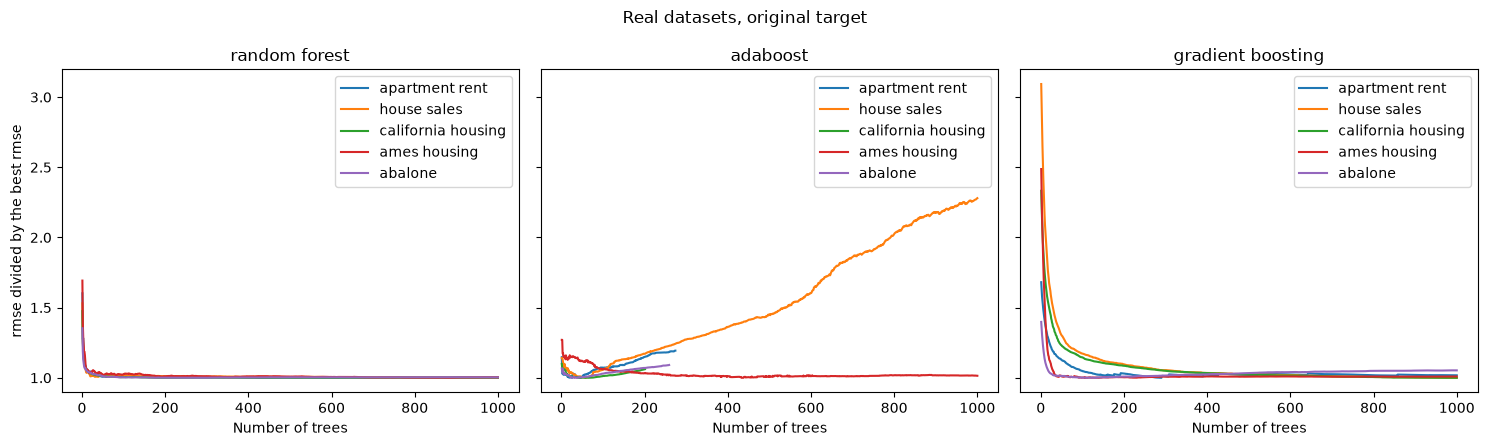

In [9]:
def plot_by_model(curves, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
    for ax, name in zip(axes, MODELS):
        for dataset in datasets:
            curve = curves[(name, dataset)]
            ax.plot(curve.index, curve / curve.min(), label=dataset)
        ax.set_xlabel("Number of trees")
        ax.set_title(name)
        ax.legend()
    axes[0].set_ylabel("rmse divided by the best rmse")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_by_model(real, "Real datasets, original target")

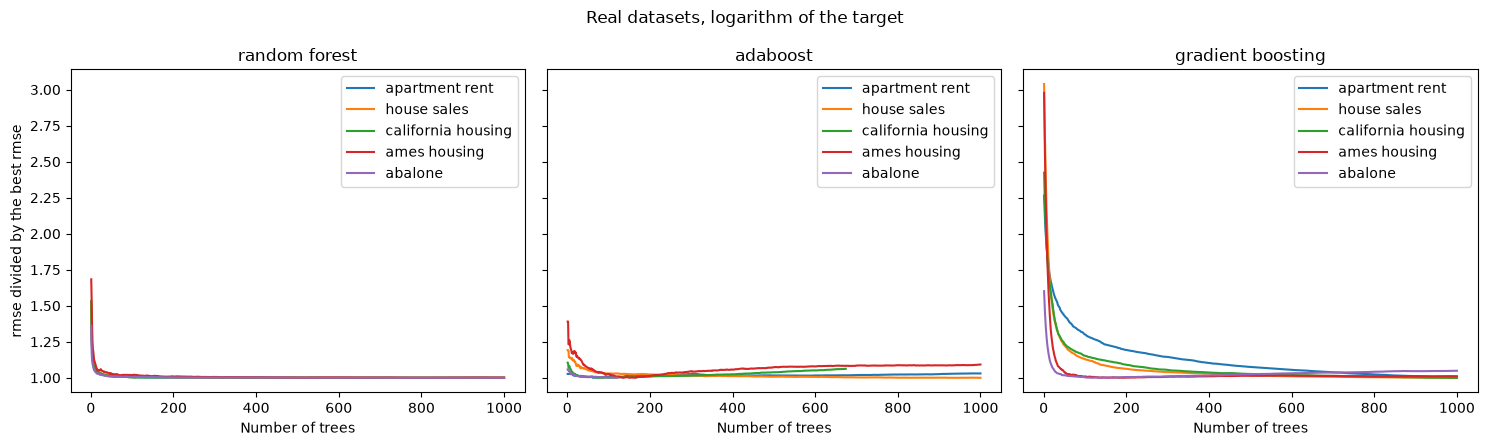

In [10]:
plot_by_model(real_logged, "Real datasets, logarithm of the target")

In [11]:
summary = pd.DataFrame({
    "lost from best %, original": {k: lost_from_best(c) for k, c in real.items()},
    "lost from best %, logarithm": {k: lost_from_best(c) for k, c in real_logged.items()},
})
summary.index.names = ["model", "dataset"]
summary.round(2)

lost from best %, original  \
model             dataset                                          
random forest     apartment rent                            0.21   
                  house sales                               0.10   
                  california housing                        0.11   
                  ames housing                              0.38   
                  abalone                                   0.32   
adaboost          apartment rent                           19.36   
                  house sales                             128.00   
                  california housing                        6.15   
                  ames housing                              1.45   
                  abalone                                   9.14   
gradient boosting apartment rent                            1.78   
                  house sales                               0.02   
                  california housing                        0.01   
                  ames housing                              0.93   
                  abalone                                   5.30   

                                      lost from best %, logarithm  
model             dataset                                          
random forest     apartment rent                             0.02  
                  house sales                                0.00  
                  california housing                         0.05  
                  ames housing                               0.17  
                  abalone                                    0.01  
adaboost          apartment rent                             3.03  
                  house sales                                0.01  
                  california housing                         6.26  
                  ames housing                               9.22  
                  abalone                                    0.03  
gradient boosting apartment rent                             0.00  
                  house sales                                0.01  
                  california housing                         0.00  
                  ames housing                               1.12  
                  abalone                                    4.90

### The learning rate

The random forest has no learning rate, because it averages its trees instead of adding them one on top of the other, so we only need to look at the two boosting models.

We train them with three learning rates, and we follow the error in the test set, one dataset per column and one model per row. We use the target as it comes, which is the case where the two models deteriorated.

In [12]:
BOOSTING = ["adaboost", "gradient boosting"]
LEARNING_RATES = [0.5, 0.1, 0.02]

rates = {
    (name, dataset, learning_rate): rmse_curve(
        name, X, y, n_estimators=500, learning_rate=learning_rate
    )
    for name in BOOSTING
    for dataset, (X, y) in datasets.items()
    for learning_rate in LEARNING_RATES
}

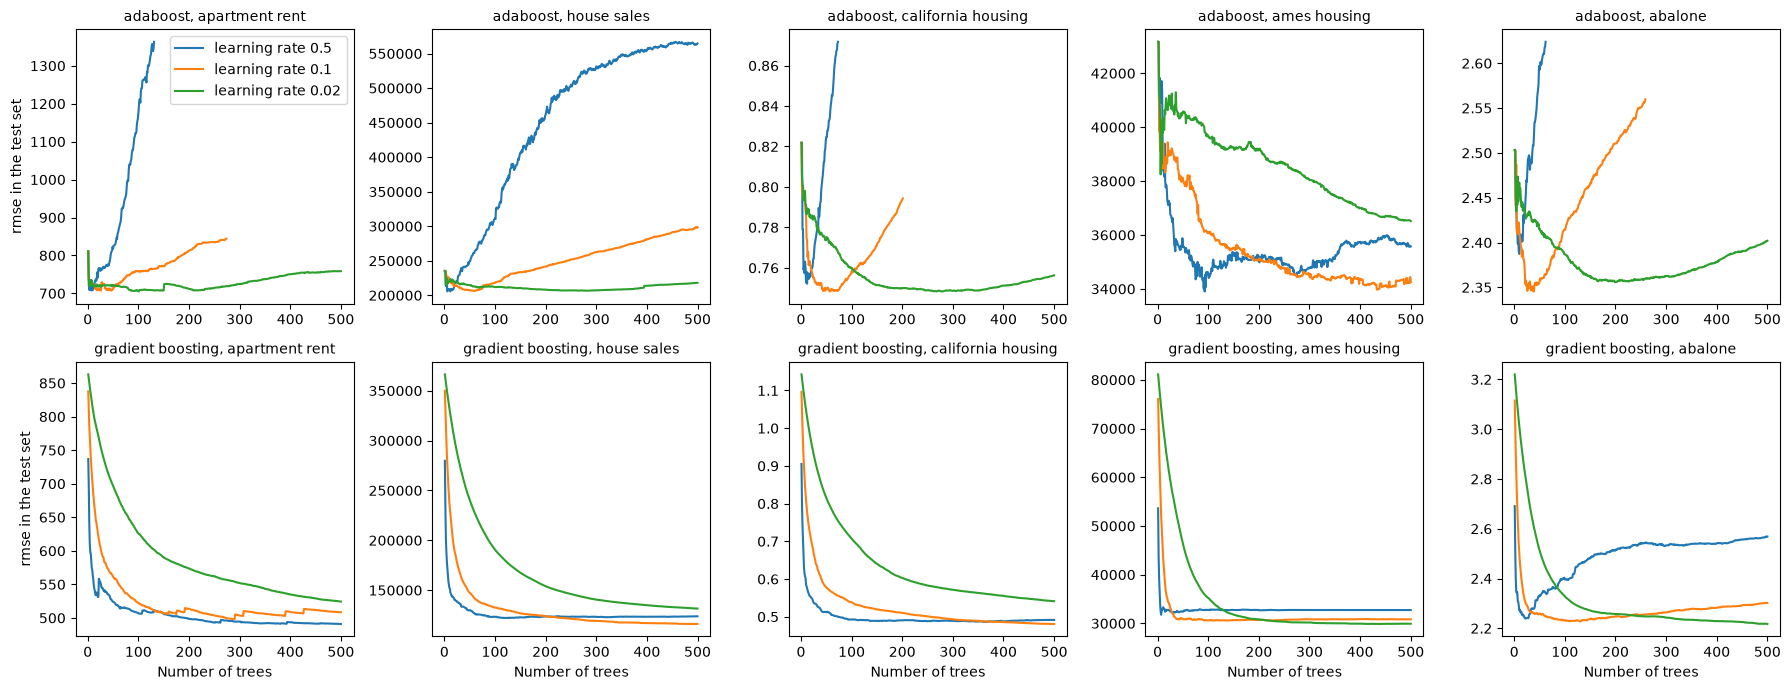

In [13]:
fig, axes = plt.subplots(len(BOOSTING), len(datasets), figsize=(18, 7))
for row, name in zip(axes, BOOSTING):
    for ax, dataset in zip(row, datasets):
        for learning_rate in LEARNING_RATES:
            curve = rates[(name, dataset, learning_rate)]
            ax.plot(curve.index, curve, label=f"learning rate {learning_rate}")
        ax.set_title(f"{name}, {dataset}", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("Number of trees")
for row in axes:
    row[0].set_ylabel("rmse in the test set")
axes[0][0].legend()
fig.tight_layout()
plt.show()

In [14]:
pd.DataFrame({
    "lost from best %": {k: lost_from_best(c) for k, c in rates.items()},
    "best rmse": {k: c.min() for k, c in rates.items()},
}).round(2)

lost from best %  best rmse
adaboost          apartment rent     0.50             92.61     707.72
                                     0.10             19.36     707.30
                                     0.02              7.61     705.06
                  house sales        0.50            174.66  205555.70
                                     0.10             44.75  206191.93
                                     0.02              5.58  206586.94
                  california housing 0.50             15.90       0.75
                                     0.10              6.15       0.75
                                     0.02              1.07       0.75
                  ames housing       0.50              4.93   33904.66
                                     0.10              0.82   33974.73
                                     0.02              0.00   36517.50
                  abalone            0.50              9.91       2.39
                                     0.10              9.14       2.35
                                     0.02              1.96       2.36
gradient boosting apartment rent     0.50              0.00     490.95
                                     0.10              2.07     498.18
                                     0.02              0.00     524.41
                  house sales        0.50              1.44  122073.85
                                     0.10              0.08  116098.10
                                     0.02              0.00  131593.36
                  california housing 0.50              1.04       0.49
                                     0.10              0.00       0.48
                                     0.02              0.00       0.54
                  ames housing       0.50              3.03   31773.30
                                     0.10              0.82   30580.35
                                     0.02              0.21   29869.08
                  abalone            0.50             14.72       2.24
                                     0.10              3.32       2.23
                                     0.02              0.00       2.22